# m12 - Learning Curves and Ensembles

**A. Data efficiency.** Only 164 native GAEZ pixels carry independent target information. How does skill grow with the number
of *training pixels*? Within every pixel-grouped CV fold, a random fraction of the training pixels is kept (10% ... 100%) and the
test pixels stay fixed. If the curve is still rising at 100%, more labelled pixels (a larger study area) would help; if it
flattens, the features are the limit.

**B. Ensembles.** Averaging out-of-fold predictions of different model families (identical folds), equal weights, no fitting of
weights on test data.

In [1]:
import sys
from pathlib import Path

# Make exp_lib importable no matter where the notebook is launched from.
HERE = next(p for p in (Path.cwd(), Path.cwd() / "scripts" / "modeling") if (p / "exp_lib.py").exists())
sys.path.insert(0, str(HERE))

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import seaborn as sns

import exp_lib as E
from threadpoolctl import threadpool_limits

threadpool_limits(E.N_JOBS)   # BLAS/OpenMP in this kernel stay within the same CPU budget as the worker pool
sns.set_theme(style="whitegrid", context="notebook")
pd.set_option("display.width", 160)

In [2]:
df = E.load_table()
targets = {c: df[f"gaez_index_{c}"].to_numpy() for c in E.CROPS}
pix = df["pix"].to_numpy()
FRACTIONS = [0.1, 0.25, 0.5, 0.75, 1.0]
N_REPEATS = 2

custom = {}
for rep in range(N_REPEATS):
    base_splits = E.make_splits(df, "pixel", seed=rep)
    rng = np.random.default_rng(rep)
    for f in FRACTIONS:
        sub = []
        for tr, te in base_splits:
            pixels = np.unique(pix[tr])
            keep = rng.choice(pixels, size=max(2, int(round(f * len(pixels)))), replace=False)
            sub.append((tr[np.isin(pix[tr], keep)], te))
        custom[f"f{f:g}_r{rep}"] = sub
n_pix = {f: np.mean([len(np.unique(pix[tr])) * f for tr, _ in E.make_splits(df, "pixel", seed=0)]) for f in FRACTIONS}
print("training pixels per fold at each fraction:", {f: round(v) for f, v in n_pix.items()})

training pixels per fold at each fraction: {0.1: 13, 0.25: 33, 0.5: 66, 0.75: 98, 1.0: 131}


## A. Learning curves

In [3]:
MODELS = ["ridge", "knn", "et", "hgb", "xgb"]
res, _ = E.run_grid(df, targets, MODELS, [], custom_splits=custom)
res[["fraction", "repeat"]] = res["scheme"].str.extract(r"f([\d.]+)_r(\d+)").astype(float)
E.save_table(res, "m12_learning_curves_raw")
lc = res.groupby(["model", "fraction"])["r2"].mean().unstack("model")
lc.index = [round(n_pix[f]) for f in lc.index]
lc.index.name = "training pixels per fold"
E.save_table(lc.round(4), "m12_learning_curves", index=True)
lc.round(3)

500 tasks (5 models x 10 targets x 10 schemes x 1 repeats), 14 features


done in 63 s


model,et,hgb,knn,ridge,xgb
training pixels per fold,,,,,
13,0.480,0.423,0.316,0.094,0.442
33,0.662,0.638,0.517,0.449,0.656
66,0.762,0.733,0.660,0.550,0.750
98,0.782,0.762,0.675,0.534,0.768
131,0.825,0.806,0.731,0.567,0.800


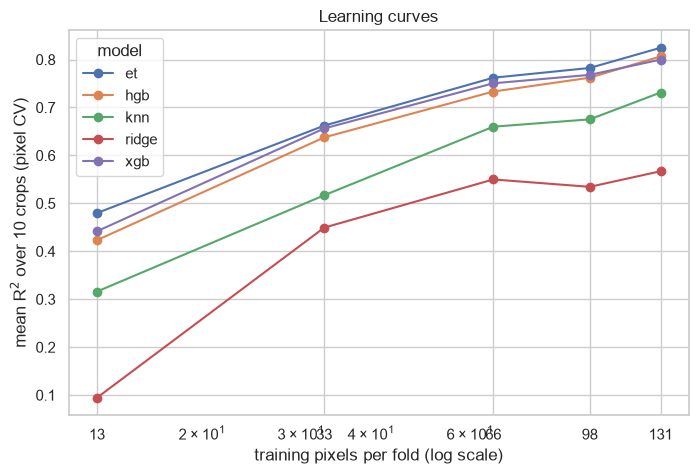

In [4]:
fig, ax = plt.subplots(figsize=(8, 5))
lc.plot(ax=ax, marker="o")
ax.set(xscale="log", xlabel="training pixels per fold (log scale)", ylabel="mean R$^2$ over 10 crops (pixel CV)", title="Learning curves")
ax.set_xticks(lc.index, [str(i) for i in lc.index])
E.save_fig(fig, "m12_learning_curves")
plt.show()

In [5]:
# Slope of the last doubling: does 50% -> 100% of the pixels still help?
half, full = lc.iloc[lc.index.get_indexer([round(n_pix[0.5])])[0]], lc.iloc[-1]
pd.DataFrame({"R2 at 50% of pixels": half, "R2 at 100%": full, "gain from doubling": full - half}).round(3).sort_values("gain from doubling")

,R2 at 50% of pixels,R2 at 100%,gain from doubling
model,,,
ridge,0.550,0.567,0.017
xgb,0.750,0.800,0.049
et,0.762,0.825,0.062
knn,0.660,0.731,0.071
hgb,0.733,0.806,0.073


## B. Ensembles of out-of-fold predictions

In [6]:
FAM = ["ridge", "knn", "et", "hgb", "xgb"]
res_e, oof = E.run_grid(df, targets, FAM, ["pixel"], n_repeats=2, keep_oof=True)
def score(members, rep):
    out = []
    for c in E.CROPS:
        p = np.mean([oof[(m, c, "pixel", rep)] for m in members], axis=0)
        out.append(E.regression_metrics(targets[c], p))
    return pd.DataFrame(out).mean()

candidates = {
    "et": ["et"], "hgb": ["hgb"], "xgb": ["xgb"],
    "et + hgb": ["et", "hgb"], "et + xgb": ["et", "xgb"], "hgb + xgb": ["hgb", "xgb"],
    "et + hgb + xgb": ["et", "hgb", "xgb"], "trees + knn": ["et", "hgb", "xgb", "knn"], "everything": FAM,
}
rows = []
for name, members in candidates.items():
    sc = pd.DataFrame([score(members, r) for r in range(2)]).mean()
    rows.append({"ensemble": name, "members": len(members), **sc.round(4).to_dict()})
ens = pd.DataFrame(rows).set_index("ensemble")
E.save_table(ens, "m12_ensembles", index=True)
ens

100 tasks (5 models x 10 targets x 1 schemes x 2 repeats), 14 features


done in 22 s


,members,r2,rmse,mae,spearman
ensemble,,,,,
et,1,0.8250,754.5596,534.5053,0.9033
hgb,1,0.8065,796.5155,558.7292,0.8932
xgb,1,0.7999,809.0560,565.2364,0.8887
et + hgb,2,0.8243,757.2590,533.5951,0.9029
et + xgb,2,0.8208,764.3510,538.8252,0.9008
hgb + xgb,2,0.8076,793.6937,555.8667,0.8934
et + hgb + xgb,3,0.8200,766.8216,539.1442,0.9004
trees + knn,4,0.8162,774.9669,548.3644,0.8992
everything,5,0.8023,804.4519,582.4876,0.8935


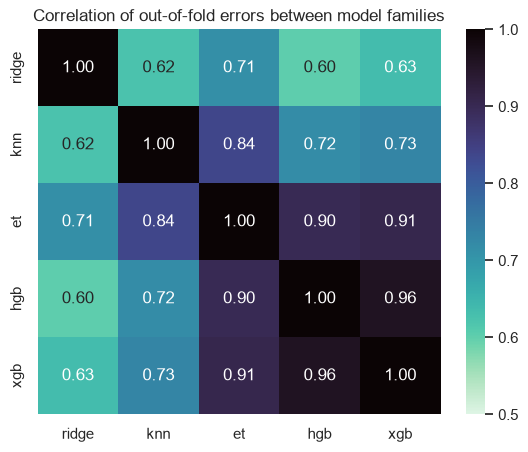

WindowsPath('D:/Softwares/AnacondaProjects/GeoSuitability_AI_Analytics/scripts/modeling/results/m12_error_correlation.csv')

In [7]:
# Error correlation between model families: diversity is what ensembling feeds on.
res_err = {m: np.concatenate([oof[(m, c, "pixel", 0)] - targets[c] for c in E.CROPS]) for m in FAM}
corr = pd.DataFrame(res_err).corr()
fig, ax = plt.subplots(figsize=(6.5, 5))
sns.heatmap(corr, annot=True, fmt=".2f", cmap="mako_r", vmin=0.5, vmax=1, ax=ax)
ax.set(title="Correlation of out-of-fold errors between model families")
E.save_fig(fig, "m12_error_correlation")
plt.show()
E.save_table(corr.round(4), "m12_error_correlation", index=True)